# DC4: NGC 4151 CPL + PL across three Figure 1 data/model cases

This notebook fits the **original three-month** DC4 NGC 4151 field with the same NGC 4151 GTI in three cases:

1. **SC on the full mock:** all 71 catalog entries, parallel-chunks temporal point responses, with only NGC 4151 CPL+PL and instrumental-background rate free.
2. **No SC on the full mock:** NGC 4151 CPL+PL plus instrumental background fitted to the **same full mock data**. The other injected sky sources are in the data but absent from this model.
3. **Isolated NGC 4151:** NGC 4151 CPL+PL plus instrumental background fitted to the original NGC 4151 event FITS selected with the same GTI. The other 70 sky sources are absent from both model and data.

In all cases the CPL index is fixed at its injected value −1.75; CPL normalization and cutoff, PL normalization and index, and the background rate are free. Independent fit starts are compared by log likelihood. A CPL-only fit with the same fixed index gives an approximate ΔTS for the added PL; its numerical floor and boundary are explained below. The source-catalog case may also compute independent SED points; NGC-only cases retain fit curves and bands only.

In [1]:
from pathlib import Path
from copy import deepcopy
import sys
import gc
import hashlib

import astropy.units as u
from astropy.coordinates import SkyCoord
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from IPython.display import display

from astromodels import (
    Cutoff_powerlaw, ExtendedSource, PointSource, Parameter, Powerlaw, Model, load_model,
)
from histpy import Histogram
from threeML import DataList, JointLikelihood, BayesianAnalysis
from threeML.minimizer.minimization import FitFailed, CannotComputeCovariance
from threeML.exceptions.custom_exceptions import BadCovariance
from cosipy.threeml import BinnedSED
from dataclasses import dataclass
from scipy.optimize import brentq, minimize

from cosipy import BinnedData
from cosipy.background_estimation import FreeNormBinnedBackground
from cosipy.data_io import EmCDSBinnedData
from cosipy.event_selection import GoodTimeInterval
from cosipy.interfaces import ThreeMLPluginInterface
from cosipy.response import (
    BinnedInstrumentResponse,
    BinnedThreeMLModelFolding,
    BinnedThreeMLPointSourceResponse,
    BinnedThreeMLExtendedSourceResponse,
    ExtendedSourceResponse,
)
from cosipy.response.FullDetectorResponse import FullDetectorResponse
from cosipy.spacecraftfile import SpacecraftHistory
from cosipy.statistics import PoissonLikelihood
from cosipy.threeml.custom_functions import GalpropHealpixModel, SpecFromDat  # noqa: F401


# DC4 recipe interpretation stays in this tutorial; reusable calculations live in cosipy.
import json
import yaml
from astropy.io import fits
from cosipy.response.temporal_profile import LightcurveProfile
from cosipy.response.threeml_temporal_response import (
    ZeroPointSourceResponse, ComponentPointSourceResponse,
    make_weighted_point_source_response,
)
from cosipy.util.megalib import megalib_map_to_galprop_fits

from threeML.plugin_prototype import PluginPrototype
from astromodels import Uniform_prior


01:56:29 WARNING   The naima package is not available. Models    functions.py:43
                  that depend on it will not be available                       
         WARNING   The GSL library or the pygsl wrapper cannot   functions.py:65
                  be loaded. Models that depend on it will not                  
                  be available.                                                 
         WARNING   The ebltable package is not available.       absorption.py:33
                  Models that depend on it will not be                          
                  available                                                     
01:56:30 INFO      Starting 3ML!                                  __init__.py:44
         WARNING   WARNINGs here are NOT errors                   __init__.py:45
         WARNING   but are inform you about optional packages     __init__.py:46
                  that can be installed                                         
         WARNING    to disab

In [2]:
def load_recipe(path, catalog_path, model):
    # A relocated recipe may be supplied in memory; retain the same validation.
    recipe = deepcopy(path) if isinstance(path, dict) else json.loads(Path(path).read_text())
    if recipe.get('schema') != 'dc4-component-lightcurve-response-v1':
        raise ValueError("Unsupported temporal-response recipe schema")
    if Path(recipe['catalog']).resolve() != Path(catalog_path).resolve():
        raise ValueError("The response recipe belongs to a different catalog")
    if recipe['selection'] not in {'full', 'NGC4151_GTI'} or recipe['time_basis'] != 'elapsed':
        raise ValueError("Expected a full-observation or NGC4151 GTI elapsed-time catalog")
    if set(row['source'] for row in recipe['components']) != set(model.sources):
        raise ValueError("Recipe and catalog source lists differ")
    if any(row['selection'] != recipe['selection'] for row in recipe['components']):
        raise ValueError("Mixed selections in response recipe")
    keys = [(r['source'], r['component']) for r in recipe['components']]
    if len(set(keys)) != len(keys):
        raise ValueError("Duplicate source/component recipe entries")
    return recipe


def component_name(source, label):
    if label in source.components:
        return label
    # v1 recipes store MEGAlib labels rather than astromodels component names.
    crab_names = {'Crab_Nebula': 'nebula', 'Crab_P1': 'peak1',
                  'Crab_Brg': 'bridge', 'Crab_P2': 'peak2'}
    if source.name == 'crab' and crab_names.get(label) in source.components:
        return crab_names[label]
    raise ValueError(f"Unknown temporal component {source.name}/{label}")


def make_temporal_responses(model, recipe, base_history, gti, data,
                            instrument_response, detector_response,
                            exposure_multiplier=1., full_history=None):
    """Build per-source/component responses from the unscaled GTI history.

    Validate temporal factors over the CATALOG selection, which can differ
    from the analysis GTI. Full catalogs require the original full_history:
    response weights remain L(t)/mean_full while exposure is GTI restricted.
    Exposure repetitions multiply response livetimes, not fluxes.
    Responses are computed lazily by cosipy and reused throughout fitting.
    """
    if not np.isfinite(exposure_multiplier) or exposure_multiplier <= 0:
        raise ValueError("Exposure multiplier must be finite and positive")
    starts, stops = np.asarray(gti.tstart_list.unix), np.asarray(gti.tstop_list.unix)
    duration = float(np.sum(stops-starts))
    if duration <= 0 or np.any(stops <= starts):
        raise ValueError("The analysis GTI must have positive duration")
    catalog_selection = recipe.get('selection', 'NGC4151_GTI')
    if catalog_selection == 'full':
        if full_history is None:
            raise ValueError("Full-observation catalogs require the original full_history")
        reference_starts = np.array([full_history.obstime[0].unix])
        reference_stops = np.array([full_history.obstime[-1].unix])
        if np.any(starts < reference_starts[0]-1e-5) or np.any(stops > reference_stops[0]+1e-5):
            raise ValueError("The analysis GTI extends beyond the catalog observation")
    elif catalog_selection == 'NGC4151_GTI':
        reference_starts, reference_stops = starts, stops
    else:
        raise ValueError(f"Unsupported catalog selection: {catalog_selection}")
    reference_duration = float(np.sum(reference_stops-reference_starts))
    if not np.isfinite(reference_duration) or reference_duration <= 0:
        raise ValueError("Invalid catalog reference duration")
    history_starts, history_stops = base_history.intervals_tstart.unix, base_history.intervals_tstop.unix
    rows_by_source = {}
    for row in recipe['components']:
        rows_by_source.setdefault(row['source'], []).append(row)
    overrides, diagnostics = {}, []
    for key, rows in rows_by_source.items():
        source = model.sources[key]
        for row in rows:
            if not np.isclose(row['selected seconds'], reference_duration, rtol=0., atol=1e-4):
                raise ValueError(f"Reference duration differs from the catalog: {key}")
        if not any(row['lightcurve'] for row in rows):
            continue
        if not isinstance(source, PointSource):
            raise NotImplementedError(f"A temporal extended response is required for {key}")
        if any(r['component'] == 'all' for r in rows) and len(rows) != 1:
            raise ValueError(f"Invalid component grouping for {key}")
        component_responses = {}
        for row in rows:
            applied = float(row['applied factor'])
            if not np.isfinite(applied) or applied <= 0:
                raise ValueError(f"Invalid applied factor for {key}")
            if row['lightcurve']:
                profile = LightcurveProfile.from_dat(
                    row['lightcurve'], expected_sha256=row['lightcurve sha256'],
                    repeating=row['repeating'], mode=row['normalization mode'],
                    bins=int(row['simulation bins']),
                )
                mean = float(profile.integral(reference_starts, reference_stops).sum()/reference_duration)
                gti_mean = float(profile.integral(starts, stops).sum()/duration)
                weights = profile.response_weights(history_starts, history_stops, applied)
                del profile
            else:
                mean, gti_mean, weights = 1., 1., np.ones(base_history.nintervals)
            if not np.isclose(mean, row['time factor'], rtol=1e-8, atol=1e-14):
                raise ValueError(f"Temporal factor differs from catalog for {key}/{row['component']}")
            if not np.isclose(applied, max(mean, 1e-30), rtol=1e-8, atol=0.):
                raise ValueError(f"Applied factor differs from catalog for {key}")
            weighted_live = base_history.livetime * weights * exposure_multiplier
            response = make_weighted_point_source_response(
                base_history, weights, data, instrument_response, detector_response,
                exposure_multiplier=exposure_multiplier,
            )
            diagnostics.append({'source': key, 'component': row['component'],
                                'normalization mode': row['normalization mode'],
                                'simulation bins': row['simulation bins'],
                                'catalog selection': catalog_selection,
                                'catalog time factor': mean,
                                'analysis GTI time factor': gti_mean,
                                'response denominator': applied,
                                'weighted response seconds': float(weighted_live.to_value(u.s).sum())})
            if row['component'] == 'all':
                overrides[key] = response
            else:
                name = component_name(source, row['component'])
                if name in component_responses:
                    raise ValueError(f"Duplicate mapped component for {key}/{name}")
                component_responses[name] = response
        if component_responses:
            if set(component_responses) != set(source.components):
                raise ValueError(f"Recipe does not cover all components of {key}")
            overrides[key] = ComponentPointSourceResponse(component_responses)
    return overrides, diagnostics


In [3]:
SPATIAL_TEMPLATE_NSIDE = 8
SPATIAL_TEMPLATE_FORMAT_TAG = "perMeV_v3"
SPATIAL_DEFINITIONS = {'positrons_26al_line': ('DC3', 'Positrons_from_26Al_line'),
 'positrons_26al_cont': ('DC3', 'Positrons_from_26Al_cont'),
 'positrons_44ti_line': ('DC3', 'Positrons_from_44Ti_line'),
 'positrons_44ti_cont': ('DC3', 'Positrons_from_44Ti_cont'),
 'narrow_bulge_511': ('DC3', 'NB_511'),
 'broad_bulge_511': ('DC3', 'BB_511'),
 'vela_snr_511': ('DC3', 'Vela_SNR_511'),
 'al26_ne2001': ('DC3', '26Al_NE2001'),
 'fe60_ne2001': ('DC3', '60Fe_NE2001'),
 'positrons_thin_disk_cont': ('DC4', 'Positrons_Thin_Disk_cont'),
 'positrons_thin_disk_line': ('DC4', 'Positrons_Thin_Disk_line')}

def resolve_source_asset(source_definition, filename):
    path = source_definition.parent / filename
    candidates = [path, Path(f"{path}.gz")]
    for candidate in candidates:
        if candidate.exists():
            return candidate.resolve()
    raise FileNotFoundError(
        f"Could not resolve {filename!r} next to {source_definition}"
    )


def parse_megalib_blocks(source_definition):
    # Return one property dictionary per DataChallenge.Source block.
    blocks = []
    by_megalib_name = {}
    for raw_line in source_definition.read_text().splitlines():
        line = raw_line.split("#", 1)[0].strip()
        if not line:
            continue
        tokens = line.split()
        if tokens[:1] == ["DataChallenge.Source"]:
            megalib_name = tokens[1]
            block = {"_name": megalib_name}
            blocks.append(block)
            by_megalib_name[megalib_name] = block
            continue
        if "." not in tokens[0]:
            continue
        megalib_name, prop = tokens[0].split(".", 1)
        if megalib_name in by_megalib_name:
            by_megalib_name[megalib_name][prop] = tokens[1:]
    if not blocks:
        raise ValueError(f"No DataChallenge.Source blocks in {source_definition}")
    return blocks


def source_library_path(value, source_library):
    """Relocate a catalog asset without relying on the original user's home."""
    parts = Path(value).parts
    if "Source_Library" not in parts:
        raise ValueError(f"Not a source-library path: {value}")
    relative = Path(*parts[parts.index("Source_Library") + 1:])
    candidate = (Path(source_library) / relative).resolve()
    if not candidate.is_file():
        raise FileNotFoundError(candidate)
    return str(candidate)


def ensure_spatial_template(source_name, output_path, source_library, overwrite=False):
    """Build only missing templates, preserving the generator's conversion."""
    output_path = Path(output_path)
    if output_path.exists() and not overwrite:
        with fits.open(output_path) as hdul:
            if (hdul['SKYMAP'].header.get('NSIDE') != SPATIAL_TEMPLATE_NSIDE
                    or hdul['SKYMAP'].header.get('MAPVERS') != SPATIAL_TEMPLATE_FORMAT_TAG):
                raise ValueError(f"Incompatible cached spatial template: {output_path}")
        return output_path, 'loaded'
    challenge, stem = SPATIAL_DEFINITIONS[source_name]
    matches = sorted((Path(source_library) / challenge / 'sources').rglob(f'{stem}.source'))
    if len(matches) != 1:
        raise ValueError(f"Expected one {stem}.source, found {matches}")
    blocks = parse_megalib_blocks(matches[0])
    if len(blocks) != 1 or len(blocks[0].get('Beam', [])) < 2:
        raise ValueError(f"Expected one coupled map in {matches[0]}")
    map_path = resolve_source_asset(matches[0], blocks[0]['Beam'][1])
    megalib_map_to_galprop_fits(
        map_path, output_path, nside=SPATIAL_TEMPLATE_NSIDE,
        oversample_nside=64, energy_bounds=(100., 10000.), overwrite=overwrite,
    )
    return output_path, 'created'


def prepare_catalog(catalog_path, recipe_input, source_library, template_directory,
                    orientation_path, response_path, binning_path, overwrite=False):
    """Generate templates, relocate external assets, and load without rewriting YAML.

    The YAML and base JSON remain byte-for-byte unchanged. Only
    the in-memory dictionaries receive this computer's paths. Their source
    amplitudes and the recipe's light-curve hashes are never modified.
    """
    from astromodels.core.model_parser import ModelParser
    from cosipy.threeml.custom_functions import GalpropHealpixModel, SpecFromDat  # noqa: F401

    catalog_path = Path(catalog_path)
    contents = yaml.safe_load(catalog_path.read_text())
    recipe = deepcopy(recipe_input)
    if Path(recipe['catalog']).name != catalog_path.name:
        raise ValueError('The recipe refers to a different catalog filename')
    recipe['catalog'] = str(catalog_path.resolve())
    for key, local in [('orientation', orientation_path), ('detector_response', response_path),
                       ('binning', binning_path)]:
        if Path(recipe[key]).name != Path(local).name:
            raise ValueError(f'{key} filename differs from the catalog recipe')
        recipe[key] = str(Path(local).resolve())
    for row in recipe['components']:
        if row['lightcurve']:
            row['lightcurve'] = source_library_path(row['lightcurve'], source_library)

    template_rows = []
    def relocate(node, source_name):
        if isinstance(node, dict):
            for key, value in node.items():
                if key == '_fitsfile' and value:
                    expected_name = f'{source_name}_nside8_perMeV_v3.fits'
                    if Path(value).name != expected_name:
                        raise ValueError(f'Unsupported spatial template: {value}')
                    path, status = ensure_spatial_template(
                        source_name, Path(template_directory) / expected_name,
                        source_library, overwrite=overwrite,
                    )
                    node[key] = str(path.resolve())
                    template_rows.append({'source': source_name, 'status': status, 'file': str(path)})
                elif isinstance(value, str) and 'Source_Library/' in value:
                    node[key] = source_library_path(value, source_library)
                else:
                    relocate(value, source_name)
        elif isinstance(node, list):
            for value in node:
                relocate(value, source_name)
    for source_key, definition in contents.items():
        relocate(definition, source_key.split(' (')[0])
    model = ModelParser(model_dict=contents).get_model()
    recipe = load_recipe(recipe, catalog_path, model)
    return model, recipe, template_rows


In [4]:
def load_selected_histogram(path, gti, binning_path, already_selected=True):
    """Load explicitly preselected HDF5 or select native FITS events before binning.

    Histogram axes do not encode their GTI. For an already-selected histogram,
    its time-selection provenance is the caller's responsibility. An unselected
    projected histogram is rejected because event times cannot be recovered.
    Native event selection uses half-open [start, stop) GTI intervals.
    """
    import astropy.units as u
    from astropy.coordinates import SkyCoord
    from histpy import Histogram, Axis, Axes, HealpixAxis

    config = yaml.safe_load(Path(binning_path).read_text())
    axes = Axes([
        Axis(config['energy_bins'], unit=u.keV, label='Em'),
        Axis(np.linspace(0., 180., int(180. / config['phi_pix_size']) + 1),
             unit=u.deg, label='Phi'),
        HealpixAxis(nside=config['nside'], scheme=config['scheme'],
                    coordsys='galactic', label='PsiChi'),
    ])
    path = Path(path)
    is_fits = path.name.endswith(('.fits', '.fits.gz'))
    if not is_fits:
        if not already_selected:
            raise ValueError('Use native event FITS to apply a new GTI, not a projected histogram')
        histogram = Histogram.open(path).project('Em', 'Phi', 'PsiChi')
        if histogram.axes != axes:
            raise ValueError(f'Histogram binning differs from agn.yaml: {path}')
        return histogram

    starts = np.asarray(gti.tstart_list.unix, dtype=float)
    stops = np.asarray(gti.tstop_list.unix, dtype=float)
    if (starts.size == 0 or np.any(stops <= starts)
            or np.any(starts[1:] < stops[:-1])):
        raise ValueError('GTI intervals must be positive, sorted and nonoverlapping')
    histogram = Histogram(axes, sparse=True)
    with fits.open(path, memmap=False) as hdul:
        events = hdul[1].data
        for offset in range(0, len(events), 250_000):
            block = events[offset:offset + 250_000]
            times = np.asarray(block['TimeTags'], dtype=float)
            if already_selected:
                selected = np.ones(times.size, dtype=bool)
            else:
                index = np.searchsorted(starts, times, side='right') - 1
                selected = (index >= 0) & (times < stops[np.maximum(index, 0)])
            direction = SkyCoord(
                l=np.asarray(block['Chi galactic'][selected]) * u.deg,
                b=np.asarray(block['Psi galactic'][selected]) * u.deg,
                frame='galactic',
            )
            histogram.fill(np.asarray(block['Energies'][selected]) * u.keV,
                           np.asarray(block['Phi'][selected]) * u.rad, direction)
    return histogram


In [5]:
# Locate the AGN tutorial from its own folder or the cosipy checkout.
notebook_dir = Path.cwd().resolve()
if not (notebook_dir / "agn_paper_plot_style.py").is_file():
    roots = [p for p in (notebook_dir, *notebook_dir.parents) if (p / "cosipy").is_dir()]
    if not roots:
        raise FileNotFoundError("Run from this tutorial folder or the cosipy checkout")
    notebook_dir = roots[0] / "docs/tutorials/spectral_fits/continuum_fit/AGN"
if str(notebook_dir) not in sys.path:
    sys.path.insert(0, str(notebook_dir))

dc4_candidates = [
    Path.home() / "Library/CloudStorage/OneDrive-ClemsonUniversity/COSI/Radio_Quiet_AGN/DC4_Files",
    Path.home() / "Library/CloudStorage/OneDrive-ClemsonUniversity/COSI/Software_Files/DC4_Files",
]
dc4_files_root = next((p for p in dc4_candidates if p.is_dir()), None)
if dc4_files_root is None:
    raise FileNotFoundError(f"DC4 files not found in {dc4_candidates}")
source_library = Path.home() / "Software/cosi-sim/cosi_sim/Source_Library"
mock_data_path = dc4_files_root / "Mock_Data/Mock_Data_Cut/dc4_mock_dataset_3months_unbinned_data_filtered_with_SAAcut_time_ordered_ngc4151_in_fov_binned.hdf5"
ngc_original_fits_path = dc4_files_root / (
    "DC4_Sources/DC4/NGC_4151_3months_unbinned_data_filtered_with_SAAcut.fits.gz"
)
background_path = dc4_files_root / (
    "Background/Total_DC4_BG_3months_binned_data_filtered_with_SAAcut_"
    "withSAAbck_NGC4151_60deg_fov_cut.hdf5"
)
orientation_path = dc4_files_root / "DC4_final_530km_3_month_with_slew_15sbins_GalacticEarth_SAA.ori"
response_path = dc4_files_root / (
    "ResponseContinuum.o3.e100_10000.b10log.s10396905069491."
    "m2284.filtered.nonsparse.binnedimaging.imagingresponse.h5"
)
agn_config = notebook_dir / "agn.yaml"
parallel_catalog_path = notebook_dir / "source_catalog_DC4_all_71files_NGC4151_GTI_elapsed_lightcurve_response_norm.yaml"
parallel_recipe_path = parallel_catalog_path.with_suffix(".response.json")
spatial_template_directory = dc4_files_root / "DC4_Sources/DC4_Spatial_Templates"
extended_response_path = dc4_files_root / (
    "Extended_Responses/NGC4151_Cut/"
    "DC4_continuum_NGC4151_60deg_GTI_extended_response_nside8.h5"
)
mock_already_gti_selected = True
background_already_gti_selected = True
exposure_multiplier = 1

for path in (source_library, mock_data_path, ngc_original_fits_path,
             background_path,
             orientation_path, response_path, agn_config, parallel_catalog_path,
             parallel_recipe_path, extended_response_path):
    if not path.exists():
        raise FileNotFoundError(path)
print("Original full mock:", mock_data_path)
print("Parallel catalog:", parallel_catalog_path)
print("Original NGC event FITS for Figure 1:", ngc_original_fits_path)
if exposure_multiplier <= 0:
    raise ValueError("exposure_multiplier must be positive")


Original full mock: /Users/parshadkp/Library/CloudStorage/OneDrive-ClemsonUniversity/COSI/Radio_Quiet_AGN/DC4_Files/Mock_Data/Mock_Data_Cut/dc4_mock_dataset_3months_unbinned_data_filtered_with_SAAcut_time_ordered_ngc4151_in_fov_binned.hdf5
Parallel catalog: /Users/parshadkp/Software/cosipy/docs/tutorials/spectral_fits/continuum_fit/AGN/source_catalog_DC4_all_71files_NGC4151_GTI_elapsed_lightcurve_response_norm.yaml
Original NGC event FITS for Figure 1: /Users/parshadkp/Library/CloudStorage/OneDrive-ClemsonUniversity/COSI/Radio_Quiet_AGN/DC4_Files/DC4_Sources/DC4/NGC_4151_3months_unbinned_data_filtered_with_SAAcut.fits.gz


In [6]:
parallel_recipe_input = json.loads(parallel_recipe_path.read_text())
parallel_model, parallel_recipe, template_status = prepare_catalog(
    parallel_catalog_path, parallel_recipe_input, source_library,
    spatial_template_directory, orientation_path, response_path, agn_config,
    overwrite=False,
)
method_models = {"parallel chunks": parallel_model}
method_recipes = {"parallel chunks": parallel_recipe}
if len(parallel_model.sources) != 71 or parallel_model.free_parameters:
    raise RuntimeError("Expected a frozen, 71-entry parallel catalog")
sc_orientation_full = SpacecraftHistory.open(orientation_path)
print("Catalog sources:", len(parallel_model.sources))
display(pd.DataFrame(template_status))


Catalog sources: 71
                      source  status  \
0        positrons_26al_line  loaded   
1        positrons_26al_cont  loaded   
2        positrons_44ti_line  loaded   
3        positrons_44ti_cont  loaded   
4           narrow_bulge_511  loaded   
5            broad_bulge_511  loaded   
6               vela_snr_511  loaded   
7                al26_ne2001  loaded   
8                fe60_ne2001  loaded   
9   positrons_thin_disk_cont  loaded   
10  positrons_thin_disk_line  loaded   

                                                 file  
0   /Users/parshadkp/Library/CloudStorage/OneDrive...  
1   /Users/parshadkp/Library/CloudStorage/OneDrive...  
2   /Users/parshadkp/Library/CloudStorage/OneDrive...  
3   /Users/parshadkp/Library/CloudStorage/OneDrive...  
4   /Users/parshadkp/Library/CloudStorage/OneDrive...  
5   /Users/parshadkp/Library/CloudStorage/OneDrive...  
6   /Users/parshadkp/Library/CloudStorage/OneDrive...  
7   /Users/parshadkp/Library/CloudStorage/OneDrive.

In [7]:
source_l = parallel_model.ngc4151.position.l.value * u.deg
source_b = parallel_model.ngc4151.position.b.value * u.deg
source_coord = SkyCoord(l=source_l, b=source_b, frame="galactic")

# These settings define the shared NGC 4151 GTI selection.
max_offaxis = 60.0 * u.deg
earth_occ = True

source_gti = GoodTimeInterval.from_pointing_cut(
    source_coord,
    sc_orientation_full,
    max_offaxis,
    earth_occ=earth_occ,
)
sc_orientation_cut = sc_orientation_full.apply_gti(source_gti)

# Repeat the selected pointing history by scaling its interval livetimes.
# The attitude and Earth-occultation selection remain unchanged.
sc_orientation = SpacecraftHistory(
    sc_orientation_cut.obstime,
    sc_orientation_cut.attitude,
    sc_orientation_cut.location,
    livetime=sc_orientation_cut.livetime * exposure_multiplier,
)
sc_orientation.cache_earth_occ = sc_orientation_cut.cache_earth_occ


full_livetime = sc_orientation_full.cumulative_livetime().to_value(u.s)
fov_livetime = sc_orientation_cut.cumulative_livetime().to_value(u.s)
scaled_livetime = sc_orientation.cumulative_livetime().to_value(u.s)
print(f"Full orientation livetime: {full_livetime:,.1f} s")
print(f"Three-month GTI livetime: {fov_livetime:,.1f} s")
print(f"Scaled {(3 * exposure_multiplier)}-month livetime: {scaled_livetime:,.1f} s")


Full orientation livetime: 6,579,555.0 s
Three-month GTI livetime: 980,415.0 s
Scaled 3-month livetime: 980,415.0 s


In [8]:
# Select the original NGC 4151 events using the same GTI as the full mock.
data_hist = load_selected_histogram(
    mock_data_path, source_gti, agn_config, already_selected=mock_already_gti_selected,
)
total_bkg = load_selected_histogram(
    background_path, source_gti, agn_config, already_selected=background_already_gti_selected,
)
ngc_original_source_hist = load_selected_histogram(
    ngc_original_fits_path, source_gti, agn_config, already_selected=False,
)
if not (total_bkg.axes == data_hist.axes == ngc_original_source_hist.axes):
    raise ValueError("Full mock, original NGC 4151, and background axes differ")
data_hist *= exposure_multiplier
total_bkg *= exposure_multiplier
ngc_original_source_hist *= exposure_multiplier
total_bkg += sys.float_info.min
comparison_data_hist_three_month = ngc_original_source_hist + total_bkg
print("Original NGC GTI event counts:",
      float(ngc_original_source_hist.to_dense(copy=False).contents.sum()))
print("Isolated NGC 4151 + background counts:",
      float(comparison_data_hist_three_month.to_dense(copy=False).contents.sum()))
bkg_dist = {"total_bkg": total_bkg}
background_rate_initial = float(total_bkg.to_dense(copy=False).contents.sum()) / scaled_livetime
if not np.isfinite(background_rate_initial) or background_rate_initial <= 0:
    raise ValueError("Invalid initial instrumental-background rate")
print(f"Initial instrumental-background rate: {background_rate_initial:.6g} Hz")
dr = FullDetectorResponse.open(str(response_path))


Original NGC GTI event counts: 54915.0
Isolated NGC 4151 + background counts: 25125949.0
Initial instrumental-background rate: 25.5719 Hz


In [9]:
# Construct the ordinary responses once; they do not depend on LC normalization.
unpolarized_components = []
for model in (parallel_model,):
    for source in model.sources.values():
        for component in source.components.values():
            degree = getattr(component.polarization, "degree", None)
            if degree is not None and degree.value != 0.0:
                degree.value = 0.0
                unpolarized_components.append(f"{source.name}.{component.name}")
print("Using unpolarized folding for:", sorted(set(unpolarized_components)))

data = EmCDSBinnedData(data_hist)
instrument_response = BinnedInstrumentResponse(dr, data)
psr = BinnedThreeMLPointSourceResponse(
    data=data, instrument_response=instrument_response, sc_history=sc_orientation,
    energy_axis=dr.axes["Ei"],
    polarization_axis=dr.axes["Pol"] if "Pol" in dr.axes.labels else None,
    nside=2 * data.axes["PsiChi"].nside,
)
if extended_response_path.exists():
    print("Loading cached GTI extended response (about 13 GiB)...")
    extended_response = ExtendedSourceResponse.open(extended_response_path)
else:
    print("Generating the NGC 4151 GTI extended response; this can be slow...")
    extended_response = dr.get_extended_source_response(
        sc_orientation_cut, coordsys="galactic", nside_image=8,
        nside_scatt_map=2 * data.axes["PsiChi"].nside, earth_occ=earth_occ,
    )
    extended_response_path.parent.mkdir(parents=True, exist_ok=True)
    extended_response.write(extended_response_path, overwrite=False)
if extended_response.axes["NuLambda"].nside != 8:
    raise ValueError("Expected an NSIDE-8 extended response")
if extended_response.axes[2:] != data.axes:
    raise ValueError("Extended response and data axes differ")
if extended_response.axes["Ei"] != dr.axes["Ei"]:
    raise ValueError("Point and extended incident-energy axes differ")
extended_response *= exposure_multiplier
esr = BinnedThreeMLExtendedSourceResponse(data=data, precomputed_psr=extended_response)
print("Shared ordinary responses are ready.")


Using unpolarized folding for: ['crab.bridge', 'crab.nebula', 'crab.peak1', 'crab.peak2', 'grb_bn080802386_flux150.bn080802386', 'grb_bn090424592.bn090424592', 'grb_bn100612726.bn100612726', 'grb_bn110605183.bn110605183', 'grb_bn131122490.bn131122490', 'grb_bn140329295.bn140329295', 'grb_bn161004964.bn161004964', 'grb_bn170405777.bn170405777', 'grb_bn180504136.bn180504136', 'grb_bn180703876.bn180703876', 'mgf_051103.mgf051103', 'mgf_070201.mgf070201', 'mgf_070222.mgf070222', 'mgf_180128a.mgf180128a', 'mgf_200415a.mgf200415a', 'mgf_231115a.mgf231115a']
Loading cached GTI extended response (about 13 GiB)...
Shared ordinary responses are ready.


In [10]:
# Original unedited DC4 injection is tabulated in the source library.
original_ngc_spectrum_path = (source_library / "DC4/sources/Extragalactic/NGC_4151/"
                              "NGC4151_ec200_TH_and_NTH_COSI.dat")
if not original_ngc_spectrum_path.exists():
    raise FileNotFoundError(original_ngc_spectrum_path)
# The MEGAlib file also contains an "IP LINLIN" interpolation directive.
with original_ngc_spectrum_path.open() as spectrum_file:
    original_spectrum = np.array([
        [float(fields[1]), float(fields[2])]
        for line in spectrum_file
        if (fields := line.split()) and fields[0] == "DP"
    ], dtype=float)
original_energy_keV, original_photon_flux = original_spectrum.T
if len(original_energy_keV) < 2 or np.any(np.diff(original_energy_keV) <= 0):
    raise ValueError("Original NGC 4151 spectrum energy samples are not increasing")

def original_injected_flux(energies_keV):
    # MEGAlib's .dat definition is linearly interpolated in energy and flux.
    return np.interp(energies_keV, original_energy_keV, original_photon_flux,
                     left=np.nan, right=np.nan)

# The isolated data file was generated with a 0.30 PL/CPL ratio at 200 keV.
injected_pl_to_cpl_at_200_keV = 0.30
spectrum_inj_cpl = Cutoff_powerlaw()
spectrum_inj_cpl.K.value = 0.15
spectrum_inj_cpl.piv.value = 1.0
spectrum_inj_cpl.xc.value = 200.0
spectrum_inj_cpl.index.value = -1.75
spectrum_inj_cpl.K.unit = 1 / (u.cm**2 * u.s * u.keV)
spectrum_inj_cpl.piv.unit = u.keV
spectrum_inj_cpl.xc.unit = u.keV
spectrum_inj_tail = Powerlaw()
spectrum_inj_tail.K.value = injected_pl_to_cpl_at_200_keV * spectrum_inj_cpl.evaluate_at(200.0)
spectrum_inj_tail.piv.value = 200.0
spectrum_inj_tail.index.value = -3.8
spectrum_inj_tail.K.unit = 1 / (u.cm**2 * u.s * u.keV)
spectrum_inj_tail.piv.unit = u.keV
spectrum_inj_isolated = spectrum_inj_cpl + spectrum_inj_tail
energy = np.geomspace(100 * u.keV, 10 * u.MeV).to_value(u.keV)
injected_flux = original_injected_flux(energy)
binned_energy_edges = data_hist.axes["Em"].edges.to_value(u.keV)
binned_energy = 0.5 * (binned_energy_edges[1:] + binned_energy_edges[:-1])
observed_counts = np.asarray(data_hist.project("Em").to_dense(copy=False).contents, dtype=float).copy()


# The original tabulated spectrum contains both thermal and non-thermal flux.
# The generator's CPL component is shown separately to judge the isolated
# CPL-only comparison at low energy.
def injected_thermal_flux(energies_keV):
    k200 = 0.15 * 200.0**(-1.75)
    e = np.asarray(energies_keV, dtype=float)
    return k200 * (e / 200.0)**(-1.75) * np.exp(-e / 200.0)

def make_fit_model(model):
    """Replace only NGC 4151's fixed injection spectrum with a free CPL."""
    assert not model.free_parameters
    source = model.ngc4151
    shape = source.spectrum.main.composite
    cpl = Cutoff_powerlaw(
        K=shape.K_1.value, piv=shape.piv_1.value,
        index=shape.index_1.value, xc=shape.xc_1.value,
    )
    fitted_source = PointSource(
        "ngc4151", l=source.position.l.value, b=source.position.b.value,
        spectral_shape=cpl,
    )
    for parameter in fitted_source.parameters.values():
        parameter.fix = True
    model.remove_source("ngc4151")
    model.add_source(fitted_source)
    shape = model.ngc4151.spectrum.main.Cutoff_powerlaw
    shape.K.min_value, shape.K.max_value = 1e-8, 1e-2
    shape.K.delta, shape.K.fix = 0.1 * shape.K.value, False
    # astromodels uses a signed exponent: photon index Γ>0 means index<0.
    # Keep the injected index -1.75 inside the allowed scan.
    shape.index.min_value, shape.index.max_value = -5., -0.01
    shape.index.delta, shape.index.fix = 0.1, False
    shape.xc.min_value, shape.xc.max_value = 100., 10000.
    shape.xc.delta, shape.xc.fix = 0.1 * shape.xc.value, False
    shape.piv.fix = True
    expected = {
        "ngc4151.spectrum.main.Cutoff_powerlaw.K",
        "ngc4151.spectrum.main.Cutoff_powerlaw.index",
        "ngc4151.spectrum.main.Cutoff_powerlaw.xc",
    }
    if set(model.free_parameters) != expected:
        raise ValueError("Catalog CPL fit must free only NGC 4151 K, index and xc")
    return model


In [11]:
def fit_joint_with_fallback(joint, label):
    """Fit the model and explicitly reject missing or invalid covariance."""
    initial_values = {name: par.value for name, par in joint._free_parameters.items()}
    try:
        joint.fit(quiet=True)
    except (FitFailed, CannotComputeCovariance, BadCovariance) as exc:
        print(f"{label}: MINUIT {type(exc).__name__}; retrying with SCIPY")
        # A failed MIGRAD may leave astromodels at its last trial point.
        # A covariance failure happens after a valid minimum, so retain it.
        if isinstance(exc, FitFailed):
            for name, par in joint._free_parameters.items():
                par.value = initial_values[name]
        joint.set_minimizer("SCIPY")
        try:
            joint.fit(quiet=True)
        except (CannotComputeCovariance, BadCovariance):
            joint.fit(quiet=True, compute_covariance=False)
    joint.restore_best_fit()
    covariance = np.atleast_2d(np.asarray(joint.results.covariance_matrix, dtype=float))
    covariance_valid = (
        np.all(np.isfinite(covariance))
        and np.all(np.diag(covariance) > 0)
    )
    if covariance_valid:
        try:
            np.linalg.cholesky(covariance)
        except np.linalg.LinAlgError:
            covariance_valid = False
    if not covariance_valid:
        print(f"{label}: no valid covariance; global 68% band is unavailable. "
              "A threeML '+/- 0' after compute_covariance=False is only a placeholder.")
    return covariance_valid


def parameter_intervals_68(results, parameters, covariance_valid):
    """Return valid covariance-based 68% intervals for fitted parameters.

    threeML's equal-tail intervals use random draws from the covariance and
    reject samples outside parameter bounds. When that truncation shifts the
    equal-tail interval away from the MLE, use the local 1-sigma covariance
    interval in the parameter's internal (possibly log) coordinates instead.
    """
    if not covariance_valid:
        return None
    covariance = np.atleast_2d(np.asarray(results.covariance_matrix, dtype=float))
    free = results.optimized_model.free_parameters
    names = list(free)
    intervals = {}
    for label, parameter in parameters.items():
        if parameter.path not in free:
            continue
        fitted_parameter = free[parameter.path]
        value = float(fitted_parameter.value)
        # A Hessian interval at a hard boundary can look spuriously tiny.
        # Report no two-sided 68% interval for a pegged parameter; use a
        # profile likelihood or a separately stated fixed-index fit instead.
        lower_bound = fitted_parameter.min_value
        upper_bound = fitted_parameter.max_value
        if lower_bound is not None and upper_bound is not None:
            bound_tolerance = 1e-5 * (float(upper_bound) - float(lower_bound))
        else:
            bound_tolerance = 1e-8 * max(abs(value), 1e-12)
        if ((lower_bound is not None and value - float(lower_bound) <= bound_tolerance)
                or (upper_bound is not None and float(upper_bound) - value <= bound_tolerance)):
            print(f"{label}: parameter is at a bound; two-sided 68% interval unavailable")
            continue
        try:
            lower, upper = map(float,
                               results.get_variates(parameter.path).equal_tail_interval(cl=0.68))
            if not (np.isfinite(lower) and np.isfinite(upper)
                    and lower <= value <= upper and lower < upper):
                raise ValueError("Bound-truncated samples do not enclose the MLE")
        except (AssertionError, BadCovariance, CannotComputeCovariance, ValueError):
            i = names.index(parameter.path)
            sigma_internal = float(np.sqrt(covariance[i, i]))
            center_internal = float(fitted_parameter._get_internal_value())
            if fitted_parameter.has_transformation():
                transform = fitted_parameter.transformation
                lower = float(transform.backward(center_internal - sigma_internal))
                upper = float(transform.backward(center_internal + sigma_internal))
            else:
                lower = center_internal - sigma_internal
                upper = center_internal + sigma_internal
            if fitted_parameter.min_value is not None:
                lower = max(lower, float(fitted_parameter.min_value))
            if fitted_parameter.max_value is not None:
                upper = min(upper, float(fitted_parameter.max_value))
            print(f"{label}: using local-covariance 68% interval because "
                  "threeML's bound-truncated equal-tail interval excludes the best fit")
        if (np.isfinite(lower) and np.isfinite(upper)
                and lower <= value <= upper and lower < upper):
            intervals[label] = [lower, upper]
        else:
            print(f"{label}: 68% interval unavailable after covariance check")
    return intervals or None


def format_parameter_68(record, label, spec):
    """Format a fitted value with asymmetric 68% errors, if they were saved."""
    value = float(record[label])
    interval = (record.get("parameter intervals 68") or {}).get(label)
    if interval is None:
        return f"{value:{spec}} (68% unavailable)"
    lower, upper = map(float, interval)
    if not (np.isfinite(lower) and np.isfinite(upper)
            and lower <= value <= upper and lower < upper):
        return f"{value:{spec}} (68% unavailable)"
    return (f"{value:{spec}} "
            f"(−{value - lower:{spec}}/+{upper - value:{spec}})")


def refresh_dc4_response_integrators():
    """Use on-disk spectral and diffuse integration code in a live kernel."""
    import importlib
    import cosipy.response.integrals as response_integrals
    import cosipy.response.functions_3d as functions_3d

    importlib.reload(response_integrals)
    importlib.reload(functions_3d)
    extended_module = importlib.import_module("cosipy.response.ExtendedSourceResponse")
    extended_module.get_integrated_extended_model_3d = (
        functions_3d.get_integrated_extended_model_3d
    )


## Three matching data and response cases

The NGC 4151-only histogram is made from the original event FITS after the same GTI cut, plus the selected instrumental-background histogram. No full-mock counts enter that isolated case. A small, total-preserving background pseudocount is applied to the **model background template** in all three fits to prevent empty detector cells from forcing an artificial source tail; the observed histograms are not altered.

In [13]:
from agn_paper_plot_style import BLUE, GREEN, ink, paper_style, style_axis

refresh_dc4_response_integrators()
BACKGROUND_PSEUDOCOUNT = 0.01
fit_background_hist = deepcopy(total_bkg)
original_background_total = float(_dense_counts(fit_background_hist).sum()) if "_dense_counts" in globals() else float(fit_background_hist.to_dense(copy=False).contents.sum())
fit_background_hist += BACKGROUND_PSEUDOCOUNT
fit_background_hist *= original_background_total / float(fit_background_hist.to_dense(copy=False).contents.sum())
assert np.all(fit_background_hist.to_dense(copy=False).contents > 0)
print("Background-model pseudocount:", BACKGROUND_PSEUDOCOUNT,
      "count per three-month detector cell; total preserved")

isolated_hist = deepcopy(comparison_data_hist_three_month)
isolated_data = EmCDSBinnedData(isolated_hist)
isolated_instrument_response = BinnedInstrumentResponse(dr, isolated_data)
isolated_psr = BinnedThreeMLPointSourceResponse(
    data=isolated_data, instrument_response=isolated_instrument_response,
    sc_history=sc_orientation, energy_axis=dr.axes["Ei"],
    polarization_axis=dr.axes["Pol"] if "Pol" in dr.axes.labels else None,
    nside=2*isolated_data.axes["PsiChi"].nside,
)

# The source-specific temporal responses are needed only for SC.
parallel_point_responses, temporal_diagnostics = make_temporal_responses(
    deepcopy(parallel_model), parallel_recipe, sc_orientation_cut, source_gti,
    data, instrument_response, dr, exposure_multiplier=exposure_multiplier,
    full_history=sc_orientation_full,
)
print("Original mock counts:", float(data_hist.to_dense(copy=False).contents.sum()))
print("Isolated NGC 4151 + background counts:",
      float(isolated_hist.to_dense(copy=False).contents.sum()))


Background-model pseudocount: 0.01 count per three-month detector cell; total preserved
Original mock counts: 26164189.0
Isolated NGC 4151 + background counts: 25125949.0


## Model and fitting helpers

Four CPL+PL starts vary the cutoff and tail strength. For each case, the CPL-only null is fitted from the best thermal component and an independent injected-like start to the same histogram and background template. A higher full-fit log likelihood is the selection rule; ΔTS is twice the difference between full and CPL-only log likelihoods. The PL normalization has a positive numerical floor of `1e-10`, so the CPL-only model is a limiting comparison. Differences below 0.01 in twice the log likelihood are treated as numerical zero. These descriptive ΔTS values are not calibrated detection significances.

In [15]:
# The original DC4 spectrum is a CPL plus a faint PL tail. Its tabulated
# total is used for plotting; starts use a 5% tail-to-CPL ratio at 200 keV.
NGC_L = parallel_model.ngc4151.position.l.value
NGC_B = parallel_model.ngc4151.position.b.value
K_CPL_INJECTED = float(parallel_model.ngc4151.spectrum.main.composite.K_1.value)
K_PL_ORIGINAL = float(0.05 * K_CPL_INJECTED * np.exp(-1.))
FIT_STARTS = (
    ("original", K_CPL_INJECTED, 200., K_PL_ORIGINAL, -3.8),
    ("weak tail", 1.2*K_CPL_INJECTED, 150., 0.2*K_PL_ORIGINAL, -2.5),
    ("strong tail", 0.8*K_CPL_INJECTED, 300., 3.*K_PL_ORIGINAL, -4.5),
    ("broad cutoff", K_CPL_INJECTED, 700., K_PL_ORIGINAL, -2.0),
)
CASE_LABELS = {
    "SC full mock": "SC on full mock",
    "No SC full mock": "No SC on full mock",
    "Isolated": "Isolated NGC 4151",
}

# The other 70 catalog sources are frozen. Compute their detector counts
# once, then fit only NGC 4151 and the background on every optimizer call.
_FIXED_SKY = None

def fixed_sky_counts():
    global _FIXED_SKY
    if _FIXED_SKY is None:
        fixed_model = deepcopy(parallel_model)
        fixed_model.remove_source("ngc4151")
        fixed_folding = BinnedThreeMLModelFolding(
            data=data, point_source_response=psr, extended_source_response=esr,
            source_specific_point_source_responses=parallel_point_responses,
        )
        fixed_folding.set_model(fixed_model)
        _FIXED_SKY = fixed_folding.expectation(copy=True)
        print("Frozen catalog counts:",
              float(_FIXED_SKY.to_dense(copy=False).contents.sum()))
        del fixed_model, fixed_folding
        gc.collect()
    return _FIXED_SKY

class FixedSkyPlusNGCFolding:
    def __init__(self, variable_folding, fixed_counts):
        self._variable = variable_folding
        self._fixed_counts = fixed_counts
        self.axes = variable_folding.axes

    def set_model(self, model):
        self._variable.set_model(model)

    def expectation(self, copy=True):
        # Background is added in place by PoissonLikelihood.
        expectation = self._variable.expectation(copy=True)
        expectation += self._fixed_counts
        return expectation

def _build_spectral_model(case, start, with_tail):
    _, K_cpl, xc, K_pl, index_pl = start
    cpl = Cutoff_powerlaw(K=K_cpl, piv=200., index=-1.75, xc=xc)
    tail = Powerlaw(K=K_pl, piv=200., index=index_pl)
    spectrum = cpl + tail if with_tail else cpl
    if case == "SC full mock":
        model = deepcopy(parallel_model)
        model.remove_source("ngc4151")
        model.add_source(PointSource("ngc4151", l=NGC_L, b=NGC_B,
                                     spectral_shape=spectrum))
        if len(model.sources) != 71:
            raise RuntimeError("SC model lost a catalog source")
    else:
        model = Model(PointSource("ngc4151", l=NGC_L, b=NGC_B,
                                  spectral_shape=spectrum))
    for parameter in model.ngc4151.parameters.values():
        parameter.fix = True
    shape = model.ngc4151.spectrum.main.shape
    if with_tail:
        shape.K_1.min_value, shape.K_1.max_value = 1e-8, 1e-2
        shape.K_1.delta, shape.K_1.fix = 0.1*shape.K_1.value, False
        shape.index_1.value, shape.index_1.fix = -1.75, True
        shape.xc_1.min_value, shape.xc_1.max_value = 20., 10000.
        shape.xc_1.delta, shape.xc_1.fix = 20., False
        shape.K_2.min_value, shape.K_2.max_value = 1e-10, 1e-2
        shape.K_2.delta, shape.K_2.fix = 0.1*shape.K_2.value, False
        shape.index_2.min_value, shape.index_2.max_value = -10., -0.5
        shape.index_2.delta, shape.index_2.fix = 0.1, False
        expected = {shape.K_1.path, shape.xc_1.path, shape.K_2.path, shape.index_2.path}
    else:
        shape.K.min_value, shape.K.max_value = 1e-8, 1e-2
        shape.K.delta, shape.K.fix = 0.1*shape.K.value, False
        shape.index.value, shape.index.fix = -1.75, True
        shape.xc.min_value, shape.xc.max_value = 20., 10000.
        shape.xc.delta, shape.xc.fix = 20., False
        expected = {shape.K.path, shape.xc.path}
    if set(model.free_parameters) != expected:
        raise RuntimeError(f"Unexpected free parameters in {case}")
    if case == "SC full mock":
        for source_name in tuple(model.sources):
            if source_name != "ngc4151":
                model.remove_source(source_name)
    return model, shape

def _fit_trial(case, start, with_tail):
    observed_data = isolated_data if case == "Isolated" else data
    observed_hist = isolated_hist if case == "Isolated" else data_hist
    ordinary_psr = isolated_psr if case == "Isolated" else psr
    model, shape = _build_spectral_model(case, start, with_tail)
    background = FreeNormBinnedBackground(
        {"total_bkg": fit_background_hist}, sc_history=sc_orientation, copy=True)
    if case == "SC full mock":
        ngc_override = parallel_point_responses.get("ngc4151")
        variable_folding = BinnedThreeMLModelFolding(
            data=observed_data, point_source_response=ordinary_psr,
            source_specific_point_source_responses=(
                {"ngc4151": ngc_override} if ngc_override is not None else None),
        )
        folding = FixedSkyPlusNGCFolding(variable_folding, fixed_sky_counts())
    else:
        folding = BinnedThreeMLModelFolding(
            data=observed_data, point_source_response=ordinary_psr,
        )
    likelihood = PoissonLikelihood(observed_data, folding, background)
    safe_case = "".join(ch if ch.isalnum() else "_" for ch in case)
    safe_start = "".join(ch if ch.isalnum() else "_" for ch in start[0])
    plugin = ThreeMLPluginInterface(
        f"cosi_{safe_case}_{safe_start}_"
        + ("full" if with_tail else "cpl"), likelihood, folding, background,
    )
    plugin.bkg_parameter["total_bkg"] = Parameter(
        "total_bkg", background_rate_initial, min_value=0., max_value=50.,
        delta=max(0.05*background_rate_initial, 1e-6), unit=u.Hz,
    )
    joint = JointLikelihood(model, DataList(plugin), verbose=False)
    initial_loglike = float(plugin.get_log_like())
    covariance_valid = fit_joint_with_fallback(
        joint, f"{case}/{start[0]}/{'CPL+PL' if with_tail else 'CPL'}")
    loglike = float(plugin.get_log_like())
    if not np.isfinite(loglike) or loglike < initial_loglike - 1e-3:
        raise RuntimeError("Fit worsened its starting likelihood")
    fitted = joint.results.optimized_model.ngc4151.spectrum.main.shape
    record = {"case": case, "start": start[0], "model": model,
              "shape": fitted, "results": joint.results,
              "background": background, "log likelihood": loglike,
              "covariance valid": bool(covariance_valid),
              "background (Hz)": float(plugin.bkg_parameter["total_bkg"].value),
              "background parameter": plugin.bkg_parameter["total_bkg"],
              "observed hist": observed_hist, "observed data": observed_data,
              "ordinary psr": ordinary_psr}
    del joint, plugin, folding, likelihood
    gc.collect()
    return record

def _best_of_starts(case, with_tail, starts=None):
    trials, best = [], None
    for start in (FIT_STARTS if starts is None else starts):
        try:
            result = _fit_trial(case, start, with_tail)
        except (FitFailed, CannotComputeCovariance, BadCovariance,
                ValueError, RuntimeError) as exc:
            trials.append({"case": case, "model": "CPL+PL" if with_tail else "CPL",
                           "start": start[0], "status": type(exc).__name__,
                           "message": str(exc)})
            print(case, start[0], "failed:", type(exc).__name__, exc)
            continue
        trials.append({"case": case, "model": "CPL+PL" if with_tail else "CPL",
                       "start": start[0], "status": "converged",
                       "log likelihood": result["log likelihood"],
                       "covariance valid": result["covariance valid"]})
        print(case, "CPL+PL" if with_tail else "CPL", start[0],
              "log L", f"{result['log likelihood']:.6f}")
        if best is None or result["log likelihood"] > best["log likelihood"] + 1e-5:
            best = result
        gc.collect()
    if best is None:
        raise RuntimeError(f"All starts failed for {case}")
    return best, pd.DataFrame(trials)

def fit_case(case):
    full, full_trials = _best_of_starts(case, True)
    # The CPL null has fewer parameters. Seed it from the winning CPL+PL
    # thermal component and one independent injected-like point.
    best_shape = full["shape"]
    null_seed = ("full-fit CPL seed", float(best_shape.K_1.value),
                 float(best_shape.xc_1.value), K_PL_ORIGINAL, -3.8)
    null, null_trials = _best_of_starts(case, False,
                                        starts=(null_seed, FIT_STARTS[0]))
    delta_ts = 2.*(full["log likelihood"] - null["log likelihood"])
    if delta_ts < -1e-2:
        raise RuntimeError(f"{case}: nested CPL+PL likelihood is worse than CPL")
    full["delta TS CPL+PL vs CPL"] = max(0., float(delta_ts))
    full["CPL-only null"] = null
    full["trials"] = pd.concat([full_trials, null_trials], ignore_index=True)
    fitted = full["shape"]
    full["parameters"] = {
        "K CPL": float(fitted.K_1.value), "index CPL (fixed)": -1.75,
        "xc (keV)": float(fitted.xc_1.value),
        "K PL": float(fitted.K_2.value), "index PL": float(fitted.index_2.value),
        "background (Hz)": full["background (Hz)"],
    }
    full["parameter intervals 68"] = parameter_intervals_68(
        full["results"], {"K CPL": fitted.K_1, "xc (keV)": fitted.xc_1,
                          "K PL": fitted.K_2, "index PL": fitted.index_2,
                          "background (Hz)": full["background parameter"]},
        full["covariance valid"],
    )
    full["fit flux"] = np.asarray([fitted.evaluate_at(e) for e in energy], dtype=float)
    full["fit flux low 68"] = full["fit flux high 68"] = None
    if full["covariance valid"]:
        try:
            def total_flux(e, K_cpl, xc, K_pl, index_pl):
                return (K_cpl*(e/fitted.piv_1.value)**(-1.75)*np.exp(-e/xc)
                        + K_pl*(e/fitted.piv_2.value)**index_pl)
            propagated = full["results"].propagate(
                total_flux,
                K_cpl=full["results"].get_variates(fitted.K_1.path),
                xc=full["results"].get_variates(fitted.xc_1.path),
                K_pl=full["results"].get_variates(fitted.K_2.path),
                index_pl=full["results"].get_variates(fitted.index_2.path),
            )
            interval = np.array([propagated(e).equal_tail_interval(cl=0.68)
                                 for e in energy])
            full["fit flux low 68"], full["fit flux high 68"] = (
                interval[:, 0], interval[:, 1])
        except (BadCovariance, CannotComputeCovariance, ValueError) as exc:
            print(case, "68% spectral band unavailable:", type(exc).__name__)
    print("\n", CASE_LABELS[case], "ΔTS(CPL+PL vs CPL) =",
          f"{full['delta TS CPL+PL vs CPL']:.3f}")
    print("CPL index: -1.75 (fixed)")
    for name, spec in (("K CPL", ".4g"), ("xc (keV)", ".4g"),
                       ("K PL", ".4g"), ("index PL", ".3g"),
                       ("background (Hz)", ".5g")):
        print(" ", name, format_parameter_68(
            {**full["parameters"], "parameter intervals 68": full["parameter intervals 68"]},
            name, spec))
    display(full["trials"])
    return full


## Fit 1 — source catalog on the full mock

In [17]:
sc_result = fit_case("SC full mock")
gc.collect()

Frozen catalog counts: 1106049.104300913
02:01:21 INFO      set the minimizer to minuit          joint_likelihood.py:1017
02:01:42 WARNING   The current value of the parameter K_1 (1.0) parameter.py:810
                  was above the new maximum 0.01.                               
         WARNING   The current value of the parameter xc_1      parameter.py:732
                  (10.0) was below the new minimum 20.0.                        
         WARNING   The current value of the parameter K_2 (1.0) parameter.py:810
                  was above the new maximum 0.01.                               
         WARNING   The current value of the parameter K_1 (1.0) parameter.py:810
                  was above the new maximum 0.01.                               
         WARNING   The current value of the parameter xc_1      parameter.py:732
                  (10.0) was below the new minimum 20.0.                        
         WARNING   The current value of the parameter K_2 (1.0) para

## Fit 2 — NGC 4151 only on the same full mock

In [19]:
no_sc_result = fit_case("No SC full mock")
gc.collect()

02:02:53 INFO      set the minimizer to minuit          joint_likelihood.py:1017
02:03:16 WARNING   92.78 percent of samples have been   analysis_results.py:1645
                  thrown away because they failed the                           
                  constraints on the parameters. This                           
                  results might not be suitable for                             
                  error propagation. Enlarge the                                
                  boundaries until you loose less than                          
                  1 percent of the samples.                                     
02:03:16 WARNING   The current value of the parameter K_1 (1.0) parameter.py:810
                  was above the new maximum 0.01.                               
         WARNING   The current value of the parameter xc_1      parameter.py:732
                  (10.0) was below the new minimum 20.0.                        
         WARNING   The curre

## Fit 3 — isolated NGC 4151 plus background

In [21]:
isolated_result = fit_case("Isolated")
gc.collect()

02:04:38 INFO      set the minimizer to minuit          joint_likelihood.py:1017
02:04:47 WARNING   84.6 percent of samples have been    analysis_results.py:1645
                  thrown away because they failed the                           
                  constraints on the parameters. This                           
                  results might not be suitable for                             
                  error propagation. Enlarge the                                
                  boundaries until you loose less than                          
                  1 percent of the samples.                                     
02:04:47 WARNING   The current value of the parameter K_1 (1.0) parameter.py:810
                  was above the new maximum 0.01.                               
         WARNING   The current value of the parameter xc_1      parameter.py:732
                  (10.0) was below the new minimum 20.0.                        
         WARNING   The curre

## Optional independent source-catalog SED

Only the source-catalog fit gets independent SED points, following the earlier Figure 1 convention. This ten-bin step is slower than the global fit and is in its own cell, so a failure cannot discard the three fitted spectra. The NGC-only comparisons have no independently calculated SED points.

In [23]:
@dataclass
class JointSEDFitResult:
    k: np.ndarray
    scaled_k: np.ndarray
    relative_nll: float
    ts: np.ndarray | None = None
    lower68: np.ndarray | None = None
    upper68: np.ndarray | None = None
    upper95: np.ndarray | None = None


class JointSEDTemplates:
    def __init__(self, background, probe_templates, probe_k, max_k):
        self.background = np.asarray(background, dtype=float).ravel()
        templates = np.asarray(probe_templates, dtype=float)
        self.probe_k = np.asarray(probe_k, dtype=float)
        self.max_k = np.asarray(max_k, dtype=float)
        if templates.ndim < 2 or templates.shape[0] != len(self.probe_k):
            raise ValueError("One detector template is required for each SED bin.")
        self.templates = templates.reshape(len(self.probe_k), -1)
        if self.templates.shape[1] != self.background.size:
            raise ValueError("Templates and background have different detector cells.")
        invalid = []
        for name, counts in (("fixed sky + instrumental background", self.background),
                             ("NGC 4151 SED templates", self.templates)):
            n_nonfinite = int(np.count_nonzero(~np.isfinite(counts)))
            n_negative = int(np.count_nonzero(counts < 0))
            if n_nonfinite or n_negative:
                invalid.append(f"{name}: {n_nonfinite} nonfinite, {n_negative} negative")
        if invalid:
            raise ValueError("Invalid Poisson counts: " + "; ".join(invalid))
        if np.any(self.probe_k <= 0) or np.any(self.max_k <= 0):
            raise ValueError("Probe and maximum normalizations must be positive.")
        self.probe_totals = self.templates.sum(axis=1)
        self.active_bins = np.flatnonzero(self.probe_totals > 0)
        if self.active_bins.size == 0:
            raise ValueError("No SED bin has a nonzero detector response.")
        self.k_scale = np.zeros(len(self.probe_k))
        self.k_scale[self.active_bins] = np.minimum(
            self.max_k[self.active_bins],
            self.probe_k[self.active_bins] * 10.0 / self.probe_totals[self.active_bins],
        )
        self.count_templates = self.templates[self.active_bins] * (
            self.k_scale[self.active_bins] / self.probe_k[self.active_bins]
        )[:, None]
        self.count_totals = self.count_templates.sum(axis=1)
        self.upper_scaled = self.max_k[self.active_bins] / self.k_scale[self.active_bins]

    def fit(self, data, initial_k=None, profile_ts=False, intervals=False):
        """Fit all K_i at once; optionally profile each bin's TS and limits."""
        data = np.asarray(data, dtype=float).ravel()
        if data.shape != self.background.shape or np.any(data < 0):
            raise ValueError("Data and background must match and be non-negative.")
        # Occupied cells without any SED response add only a constant to the
        # likelihood. Excluding them also avoids huge ratios from tiny empty
        # background-template cells.
        responsive = np.any(self.count_templates > 0, axis=0)
        occupied = (data > 0) & responsive
        background = self.background[occupied]
        if np.any(background <= 0):
            raise ValueError("Background must be positive in responsive data cells.")
        observed = data[occupied]
        templates = self.count_templates[:, occupied]
        totals = self.count_totals
        n_free = len(self.active_bins)
        # Keep free amplitudes just above zero during optimization. The null
        # value remains exactly zero for TS profiling. With a subnormal
        # instrumental-background floor, an optimizer trial at x=0 can give
        # a ~1e242 score and make L-BFGS-B report ABNORMAL.
        lower_scaled = np.minimum(1e-8, 1e-3 * self.upper_scaled)
        bounds = list(zip(lower_scaled, self.upper_scaled))
        if initial_k is None:
            x0 = np.ones(n_free)
        else:
            initial_k = np.asarray(initial_k, dtype=float)
            x0 = initial_k[self.active_bins] / self.k_scale[self.active_bins]
            x0 = np.clip(x0, lower_scaled, self.upper_scaled)
        # The probe scaling targets roughly ten counts per active bin. Avoid
        # starting all bins at zero when the preceding global CPL fit is weak.
        x0 = np.maximum(x0, np.minimum(1.0, self.upper_scaled))
        reference = background + x0 @ templates
        if np.any(reference <= 0) or np.any(~np.isfinite(reference)):
            raise ValueError("The initial SED model has invalid Poisson expectations.")
        log_reference = np.log(reference)

        def objective(x):
            source = x @ templates
            expected = background + source
            if np.any(expected <= 0) or np.any(~np.isfinite(expected)):
                return np.inf, np.full(n_free, np.nan)
            # log(expected)-log(reference) stays finite when the background
            # is subnormal. log1p(source/background) can overflow to infinity.
            value = float(totals @ x - observed @ (np.log(expected) - log_reference))
            ratio = observed / np.maximum(expected, 1e-250)
            gradient = totals - templates @ ratio
            return value, gradient

        optimum = minimize(
            objective, x0, method="L-BFGS-B", jac=True, bounds=bounds,
            options={"maxiter": 2000, "ftol": 1e-12, "gtol": 1e-6},
        )
        if not optimum.success or not np.isfinite(optimum.fun):
            retry_start = np.minimum(np.ones(n_free), self.upper_scaled)
            optimum = minimize(
                objective, retry_start, method="L-BFGS-B", jac=True, bounds=bounds,
                options={"maxiter": 5000, "maxls": 80, "ftol": 1e-12, "gtol": 1e-7},
            )
        if not optimum.success or not np.isfinite(optimum.fun):
            raise RuntimeError(
                f"Joint BinnedSED fit failed: {optimum.message}; "
                f"active bins={self.active_bins.tolist()}, "
                f"probe totals={self.probe_totals.tolist()}"
            )
        best = np.asarray(optimum.x, dtype=float)
        best_nll = float(objective(best)[0])
        k = np.zeros(len(self.probe_k))
        k[self.active_bins] = best * self.k_scale[self.active_bins]
        result = JointSEDFitResult(k=k, scaled_k=best, relative_nll=best_nll)
        if not profile_ts and not intervals:
            return result

        def profile_nll(local_index, fixed_value):
            if fixed_value == best[local_index]:
                return best_nll
            other = np.arange(n_free) != local_index
            trial = best.copy()
            trial[local_index] = fixed_value
            if not np.any(other):
                return float(objective(trial)[0])

            def other_objective(values):
                trial[other] = values
                value, gradient = objective(trial)
                return value, gradient[other]

            profiled = minimize(
                other_objective, best[other], method="L-BFGS-B", jac=True,
                bounds=[bounds[i] for i in np.flatnonzero(other)],
                options={"maxiter": 500, "ftol": 1e-12, "gtol": 1e-6},
            )
            if not profiled.success:
                profiled = minimize(
                    other_objective, profiled.x, method="SLSQP", jac=True,
                    bounds=[bounds[i] for i in np.flatnonzero(other)],
                    options={"maxiter": 500, "ftol": 1e-9},
                )
            if not profiled.success or not np.isfinite(profiled.fun):
                raise RuntimeError(f"SED bin {local_index} profile failed: {profiled.message}")
            return float(profiled.fun)

        ts = np.zeros(len(self.probe_k))
        lower68 = np.zeros(len(self.probe_k))
        upper68 = np.full(len(self.probe_k), np.nan)
        upper95 = np.full(len(self.probe_k), np.nan)
        for j, bin_index in enumerate(self.active_bins):
            null_nll = profile_nll(j, 0.0)
            ts[bin_index] = max(0.0, 2.0 * (null_nll - best_nll))
            if not intervals:
                continue

            def delta(value):
                return max(0.0, 2.0 * (profile_nll(j, value) - best_nll))

            if best[j] > 0 and ts[bin_index] > 1.0:
                lower_scaled = brentq(
                    lambda value: delta(value) - 1.0, 0.0, best[j],
                    xtol=1e-8, rtol=1e-7,
                )
                lower68[bin_index] = lower_scaled * self.k_scale[bin_index]

            def upper_root(target):
                lo = best[j]
                hi = min(self.upper_scaled[j], max(lo + 1.0, lo * 2.0))
                while delta(hi) < target and hi < self.upper_scaled[j]:
                    hi = min(self.upper_scaled[j], hi * 2.0)
                if delta(hi) < target:
                    return float("nan")
                return brentq(
                    lambda value: delta(value) - target, lo, hi,
                    xtol=1e-8, rtol=1e-7,
                ) * self.k_scale[bin_index]

            upper68[bin_index] = upper_root(1.0)
            upper95[bin_index] = upper_root(2.705543)
        result.ts = ts
        if intervals:
            result.lower68 = lower68
            result.upper68 = upper68
            result.upper95 = upper95
        return result


In [24]:
class WeakBinPoissonLike(PluginPrototype):
    """Precomputed detector-count likelihood for one weak SED-bin amplitude."""
    def __init__(self, name, base_counts, source_counts, observed, amplitude_parameter, total_source_counts):
        super().__init__(name, {})
        self.base = np.asarray(base_counts, dtype=float)
        self.template = np.asarray(source_counts, dtype=float)
        self.data = np.asarray(observed, dtype=float)
        self.amplitude_parameter = amplitude_parameter
        if np.any(self.base <= 0) or np.any(self.template < 0):
            raise ValueError("Invalid Bayesian Poisson template")
        self.reference = np.log(self.base + self.template)
        self.total_template = float(total_source_counts)

    def set_model(self, likelihood_model):
        self._likelihood_model = likelihood_model

    def get_log_like(self):
        x = float(self.amplitude_parameter.value)
        if x < 0:
            return -np.inf
        expected = self.base + x * self.template
        if np.any(expected <= 0) or np.any(~np.isfinite(expected)):
            return -np.inf
        # Constant terms cancel; nonresponsive occupied cells are omitted.
        return float(self.data @ (np.log(expected) - self.reference)
                     - x * self.total_template)

    def inner_fit(self):
        return self.get_log_like()

    def get_number_of_data_points(self):
        return int(self.data.size)


def bayesian_weak_limits(template_fit, fit_result, observed_hist, *, label):
    """Replace only TS<1 profile ULs with 95% threeML posterior quantiles."""
    observed = _dense_counts(observed_hist).ravel()
    active = template_fit.active_bins
    responsive = np.any(template_fit.count_templates > 0, axis=0)
    occupied = (observed > 0) & responsive
    count_templates = template_fit.count_templates[:, occupied]
    best = fit_result.scaled_k.copy()
    bayes_ul = np.full(len(template_fit.probe_k), np.nan)
    diagnostics = []
    for j, bin_index in enumerate(active):
        if fit_result.ts[bin_index] >= 1.0:
            continue
        source_all = count_templates[j]
        relevant = source_all > 0
        if not np.any(relevant):
            continue
        source = source_all[relevant]
        # Form the other-bin model directly. Subtracting one tiny component
        # from a large baseline can cancel the subnormal background to zero.
        other = np.arange(len(active)) != j
        base = (template_fit.background[occupied][relevant]
                + best[other] @ count_templates[other][:, relevant])
        if np.any(base <= 0):
            raise RuntimeError(f"{label}: nonpositive baseline in weak SED bin {bin_index+1}")
        profile_ul = fit_result.upper95[bin_index]
        scaled_profile = profile_ul / template_fit.k_scale[bin_index] if np.isfinite(profile_ul) else 0.
        prior_max = min(template_fit.upper_scaled[j], max(30., 20. * scaled_profile, 20. * best[j]))
        if not np.isfinite(prior_max) or prior_max <= 0:
            raise RuntimeError(f"{label}: invalid prior bound in SED bin {bin_index+1}")
        dummy = PointSource(f"weak_bin_{bin_index+1}", l=0., b=0.,
                            spectral_shape=Powerlaw(K=min(1., prior_max/2.),
                                                    piv=1000., index=-2.))
        posterior_model = Model(dummy)
        amplitude = posterior_model.point_sources[dummy.name].spectrum.main.Powerlaw.K
        for par in dummy.parameters.values():
            par.fix = True
        amplitude.fix = False
        # Powerlaw.K has a logarithmic transform in astromodels and therefore
        # needs a strictly positive numerical minimum. The uniform prior
        # still starts at zero; this 1e-12 floor has negligible mass.
        amplitude.min_value, amplitude.max_value = max(1e-12, 1e-12*prior_max), float(prior_max)
        amplitude.prior = Uniform_prior(lower_bound=0., upper_bound=float(prior_max))
        plugin = WeakBinPoissonLike(
            f"weak_bin_like_{bin_index+1}", base, source,
            observed[occupied][relevant], amplitude,
            total_source_counts=template_fit.count_totals[j],
        )
        analysis = BayesianAnalysis(posterior_model, DataList(plugin))
        analysis.set_sampler("emcee")
        analysis.sampler.setup(n_walkers=20, n_iterations=1800, n_burn_in=600,
                               seed=1400 + bin_index)
        analysis.sample(quiet=True)
        draws = np.asarray(analysis.samples[amplitude.path], dtype=float)
        q95 = float(np.quantile(draws, 0.95))
        if not np.isfinite(q95) or q95 >= 0.9 * prior_max:
            raise RuntimeError(f"{label}: weak-bin posterior hits its prior bound in bin {bin_index+1}")
        bayes_ul[bin_index] = q95 * template_fit.k_scale[bin_index]
        diagnostics.append(dict(bin=int(bin_index+1), TS=float(fit_result.ts[bin_index]),
                                prior_max_K=float(prior_max * template_fit.k_scale[bin_index]),
                                upper95_K=float(bayes_ul[bin_index]),
                                draws=int(draws.size)))
        print(f"{label} SED bin {bin_index+1}: TS={fit_result.ts[bin_index]:.2f}, "
              f"Bayesian 95% K UL={bayes_ul[bin_index]:.4g}")
    return bayes_ul, diagnostics


In [25]:
def _dense_counts(histogram):
    """Copy histogram values because response caches reuse their buffers."""
    values = histogram.to_dense(copy=False).contents
    if hasattr(values, "compute"):
        values = values.compute()
    if hasattr(values, "value"):
        values = values.value
    return np.asarray(values, dtype=float).copy()


def extract_binned_sed(model, global_shape, point_responses, background, *,
                       observed_hist, data_object, ordinary_psr, extended_psr, label, counts_scale=1.):
    """Fit independent NGC 4151 Ei-bin amplitudes for one catalog method."""
    edges = dr.axes["Ei"].edges.to_value(u.keV)
    if len(edges) != 11 or not np.allclose(edges[[0, -1]], [100., 10000.], rtol=1e-4):
        raise ValueError("Expected the native 10-bin, 0.1–10 MeV Ei response axis")
    pivots = np.sqrt(edges[:-1] * edges[1:])
    initial_k = np.asarray([global_shape.evaluate_at(e) for e in pivots], dtype=float)
    # Omit spectral_shape intentionally: BinnedSED defaults to a fixed E^-2
    # power law within every Ei bin. CPL values only initialize the optimizer.
    sed = BinnedSED.from_response(dr, initial_fluxes=initial_k)
    if not np.isclose(sed.spectral_shape.index.value, -2.0):
        raise RuntimeError("Expected BinnedSED default power-law index -2")
    source = model.ngc4151
    sed_source = PointSource(
        "ngc4151", l=source.position.l.value, b=source.position.b.value,
        spectral_shape=sed,
    )
    model.remove_source("ngc4151")
    model.add_source(sed_source)
    sed_shape = model.ngc4151.spectrum.main.shape
    for parameter in sed_shape.normalizations:
        parameter.value = 0.
        parameter.fix = True

    # A fresh folding object is essential: the global-fit folding object
    # caches its old ngc4151 source response under the same source name.
    sed_folding = BinnedThreeMLModelFolding(
        data=data_object, point_source_response=ordinary_psr, extended_source_response=extended_psr,
        source_specific_point_source_responses=point_responses,
    )
    sed_folding.set_model(model)
    fixed_sky = _dense_counts(sed_folding.expectation(copy=False))
    fixed_background = _dense_counts(background.expectation(copy=True))
    if not np.isfinite(counts_scale) or counts_scale <= 0:
        raise ValueError("counts_scale must be finite and positive")
    fixed_counts = counts_scale * (fixed_sky + fixed_background)
    # The source response is already bound to this model by expectation().
    # Read its counts directly. Subtracting two full-catalog predictions can
    # erase a faint NGC 4151 probe through floating-point cancellation.
    ngc_response = sed_folding._source_responses["ngc4151"]
    max_k = np.asarray([p.max_value for p in sed_shape.normalizations], dtype=float)
    probe_k = np.minimum(max_k, np.maximum(initial_k, 1e-5))
    templates = []
    for i, parameter in enumerate(sed_shape.normalizations):
        parameter.value = float(probe_k[i])
        template = _dense_counts(ngc_response.expectation(copy=False))
        if np.min(template) < -1e-7 * max(np.max(template), 1.):
            raise RuntimeError(f"Ei bin {i} produced negative source counts")
        templates.append(counts_scale * np.maximum(template, 0.))
        parameter.value = 0.
    template_fit = JointSEDTemplates(fixed_counts, np.asarray(templates), probe_k, max_k)
    fitted = template_fit.fit(
        _dense_counts(observed_hist), initial_k=initial_k, profile_ts=True, intervals=True,
    )
    bayes_upper95, bayes_diagnostics = bayesian_weak_limits(
        template_fit, fitted, observed_hist, label=label,
    )
    upper95 = np.asarray(fitted.upper95, dtype=float).copy()
    weak = fitted.ts < 1.0
    upper95[weak & np.isfinite(bayes_upper95)] = bayes_upper95[weak & np.isfinite(bayes_upper95)]
    result = {
        "bayesian upper 95": bayes_upper95,
        "bayesian diagnostics": bayes_diagnostics,
        "upper limit method": np.where(weak & np.isfinite(bayes_upper95),
                                       "Bayesian 95%", "profile 95%"),
        "edges keV": edges, "pivot keV": pivots, "K": fitted.k,
        "TS": fitted.ts, "lower 68": fitted.lower68,
        "upper 68": fitted.upper68, "upper 95": upper95,
        "spectral shape": "Powerlaw(index=-2)",
    }
    print(f"SED: {np.sum(fitted.ts >= 4)} bins at TS >= 4 of {len(pivots)} Ei bins")
    return result


In [26]:
RUN_CATALOG_SED = True
if RUN_CATALOG_SED:
    # extract_binned_sed replaces ngc4151 with ten independent E^-2 bins.
    # Keep the completed CPL+PL best fit and its uncertainties intact.
    sed_model = deepcopy(parallel_model)
    sed_model.remove_source("ngc4151")
    sed_model.add_source(deepcopy(sc_result["model"].ngc4151))
    sc_result["sed"] = extract_binned_sed(
        sed_model, sc_result["shape"], parallel_point_responses,
        sc_result["background"], observed_hist=data_hist,
        data_object=data, ordinary_psr=psr, extended_psr=esr,
        label="CPL+PL source catalog",
    )


         WARNING   The current value of the parameter K_1 (1.0) parameter.py:810
                  was above the new maximum 0.01.                               
         WARNING   The current value of the parameter xc_1      parameter.py:732
                  (10.0) was below the new minimum 20.0.                        
         WARNING   The current value of the parameter K_2 (1.0) parameter.py:810
                  was above the new maximum 0.01.                               
02:10:18 INFO      sampler set to emcee                 bayesian_analysis.py:186
100%|##########| 1800/1800 [00:05<00:00, 339.62it/s]
02:10:25 INFO      Mean acceptance fraction:                emcee_sampler.py:145
                  0.8051111111111112                                            
         INFO      fit restored to maximum of posterior      sampler_base.py:168
         INFO      fit restored to maximum of posterior      sampler_base.py:168
CPL+PL source catalog SED bin 1: TS=0.25, Bayesian 95% K

## Results and white-background figure

All three curves use the same injected original NGC 4151 reference. The SC and No SC curves fit the full mock; the isolated curve fits only NGC 4151 plus instrumental background. The light-blue SED symbols, when enabled, belong only to the source-catalog fit.

                 case                   data     K CPL    xc (keV)  \
0     SC on full mock              full mock  0.000003  814.609346   
1  No SC on full mock              full mock  0.000017  502.889681   
2   Isolated NGC 4151  NGC 4151 + background  0.000012  226.887509   

           K PL  index PL  background (Hz)  log L CPL+PL     log L CPL  \
0  6.110471e-09 -1.910965        25.519375  1.181031e+08  1.181031e+08   
1  1.077202e-10 -2.385380        26.527204  1.180932e+08  1.180932e+08   
2  2.858938e-10 -2.191307        25.569980  1.122590e+08  1.122590e+08   

   delta TS  covariance valid  
0       0.0              True  
1       0.0              True  
2       0.0              True  

WARNING UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown



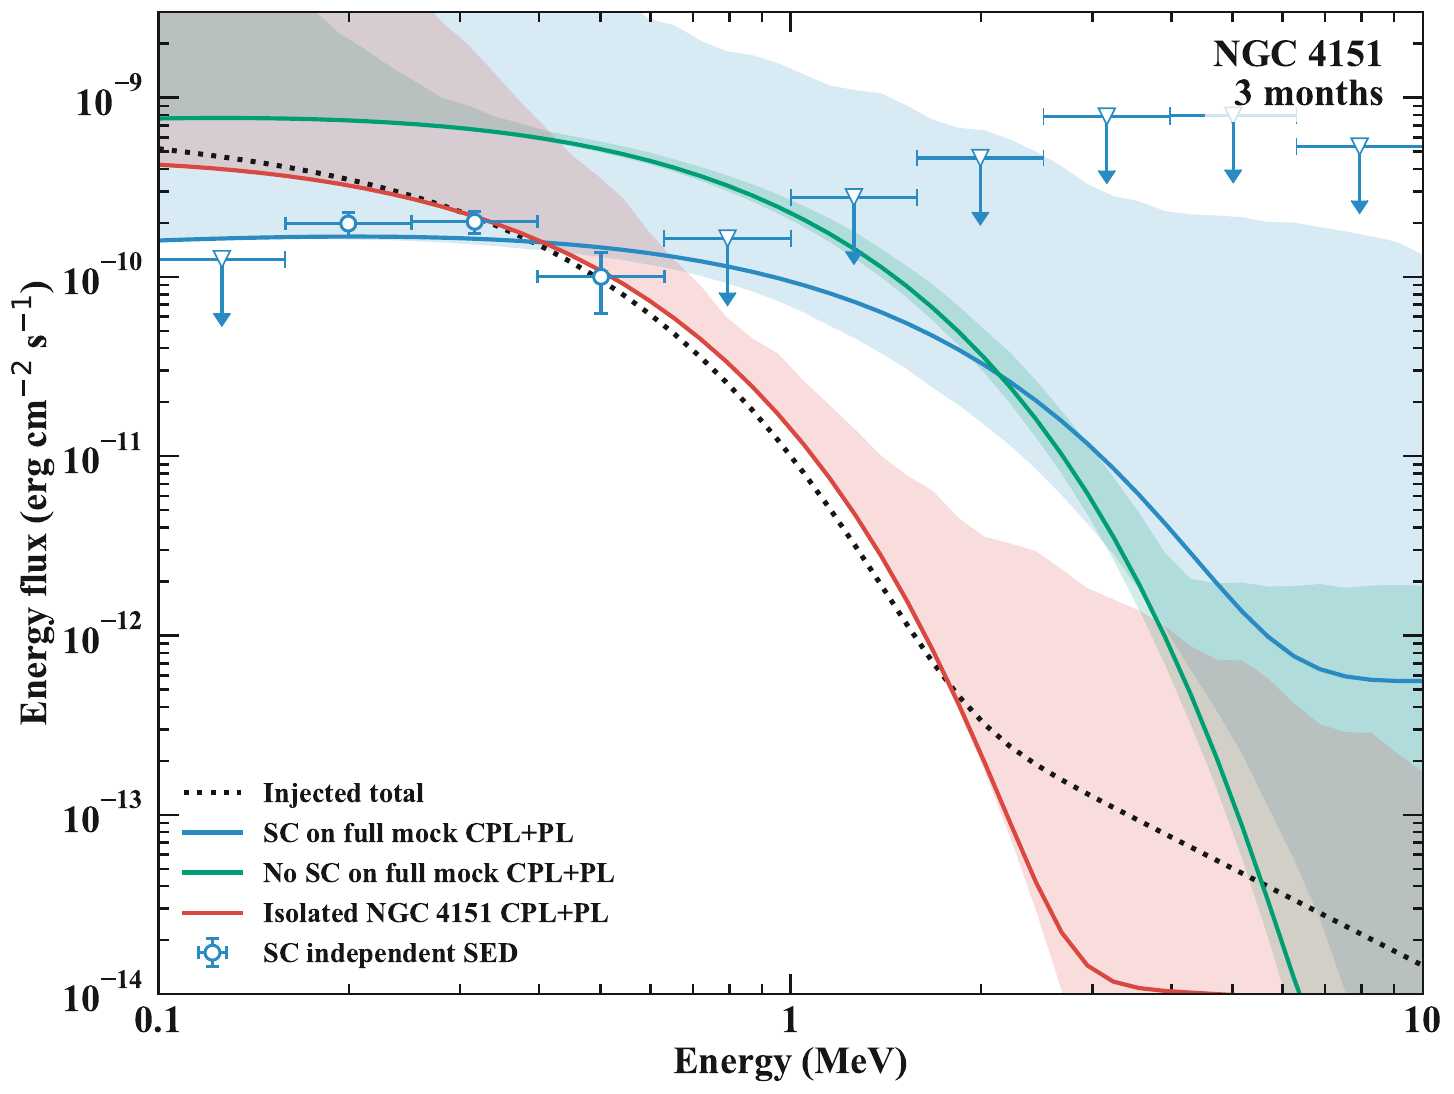

In [28]:
FIT_RESULTS = (sc_result, no_sc_result, isolated_result)
summary = pd.DataFrame([
    {"case": CASE_LABELS[item["case"]],
     "data": "full mock" if item["case"] != "Isolated" else "NGC 4151 + background",
     "K CPL": item["parameters"]["K CPL"],
     "xc (keV)": item["parameters"]["xc (keV)"],
     "K PL": item["parameters"]["K PL"],
     "index PL": item["parameters"]["index PL"],
     "background (Hz)": item["parameters"]["background (Hz)"],
     "log L CPL+PL": item["log likelihood"],
     "log L CPL": item["CPL-only null"]["log likelihood"],
     "delta TS": item["delta TS CPL+PL vs CPL"],
     "covariance valid": item["covariance valid"]}
    for item in FIT_RESULTS
])
display(summary)
output_dir = notebook_dir / "plots"
output_dir.mkdir(parents=True, exist_ok=True)
summary.to_csv(output_dir / "NGC4151_DC4_three_case_CPLPL_original_mock_summary.csv", index=False)

KEV_TO_ERG = u.keV.to(u.erg)
COLORS = {"SC full mock": BLUE, "No SC full mock": GREEN,
          "Isolated": "#D94841"}
with paper_style("light", 23):
    fig, ax = plt.subplots(figsize=(12, 9), constrained_layout=True)
    style_axis(ax, "light", 23)
    ax.plot(energy/1000., KEV_TO_ERG*energy**2*original_injected_flux(energy),
            color=ink("light"), ls=":", lw=3, label="Injected total")
    for result in FIT_RESULTS:
        color = COLORS[result["case"]]
        ax.plot(energy/1000., KEV_TO_ERG*energy**2*result["fit flux"],
                color=color, lw=2.5,
                label=CASE_LABELS[result["case"]] + " CPL+PL")
        if result["fit flux low 68"] is not None:
            ax.fill_between(energy/1000.,
                            KEV_TO_ERG*energy**2*np.where(
                                result["fit flux low 68"] > 0,
                                result["fit flux low 68"], np.nan),
                            KEV_TO_ERG*energy**2*np.where(
                                result["fit flux high 68"] > 0,
                                result["fit flux high 68"], np.nan),
                            color=color, alpha=0.18, linewidth=0)
    if "sed" in sc_result:
        sed = sc_result["sed"]
        pivot = np.asarray(sed["pivot keV"], dtype=float)
        edges = np.asarray(sed["edges keV"], dtype=float)
        detected = ((sed["TS"] >= 4.) & (sed["K"] > 0.)
                    & (sed["lower 68"] > 0.) & np.isfinite(sed["upper 68"]))
        upper = (~detected) & np.isfinite(sed["upper 95"]) & (sed["upper 95"] > 0.)
        if np.any(detected):
            p, k = pivot[detected], sed["K"][detected]
            ax.errorbar(p/1000., KEV_TO_ERG*p**2*k,
                        xerr=np.vstack((p-edges[:-1][detected],
                                        edges[1:][detected]-p))/1000.,
                        yerr=np.vstack((KEV_TO_ERG*p**2*(k-sed["lower 68"][detected]),
                                        KEV_TO_ERG*p**2*(sed["upper 68"][detected]-k))),
                        fmt="o", color=BLUE, markerfacecolor="white",
                        markeredgewidth=1.8, markersize=9, capsize=4,
                        label="SC independent SED")
        if np.any(upper):
            p = pivot[upper]
            limits = KEV_TO_ERG*p**2*sed["upper 95"][upper]
            ax.errorbar(p/1000., limits,
                        xerr=np.vstack((p-edges[:-1][upper],
                                        edges[1:][upper]-p))/1000.,
                        yerr=np.maximum(0.5*limits, np.finfo(float).tiny),
                        uplims=True, fmt="v", color=BLUE,
                        markerfacecolor="white", markersize=10, capsize=5)
    ax.set(xscale="log", yscale="log", xlim=(0.1, 10.),
           ylim=(1e-14, 3e-9), xlabel="Energy (MeV)",
           ylabel=r"Energy flux (erg cm$^{-2}$ s$^{-1}$)")
    ax.xaxis.set_major_locator(mticker.FixedLocator([0.1, 1., 10.]))
    ax.xaxis.set_major_formatter(mticker.FixedFormatter(["0.1", "1", "10"]))
    ax.text(0.97, 0.97, "NGC 4151\n3 months", transform=ax.transAxes,
            ha="right", va="top", fontsize=23,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.78, pad=5))
    ax.legend(loc="lower left", frameon=False, fontsize=17)
    fig.savefig(output_dir / "NGC4151_DC4_three_case_CPLPL_original_mock_white.pdf",
                facecolor="white", transparent=False, bbox_inches="tight")
    plt.show()
